# RNA – Projeto Prático 2.1: Aprendizado Supervisionado no Neurônio Perceptron
Equipe com identificador **0** (arquivos `data020262.txt`, semente = 0).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from neuron import PerceptronNeuron

ID_EQUIPE = 0

def carregar(caminho):
    d = np.load(caminho, allow_pickle=True).reshape(-1, 3)
    return d[:, :2], d[:, 2].astype(int)

## Parte I – Problema linearmente separável (`dataAll20262.txt`)
Ativação degrau (ϑ = 0), η = 0,1, pesos ~ U(−0,5; 0,5), treino até a convergência.

Exemplos: 1000
Vetor inicial de pesos [w0, w1, w2]: [ 0.05632216 -0.35575962  0.47884499]


Vetor final de pesos   [w0, w1, w2]: [-4.36778359e-02  8.61123929e+01 -4.25480030e+02]
(a) Número total de ajustes no vetor de pesos: 65
(b) Número de épocas até a convergência:       4


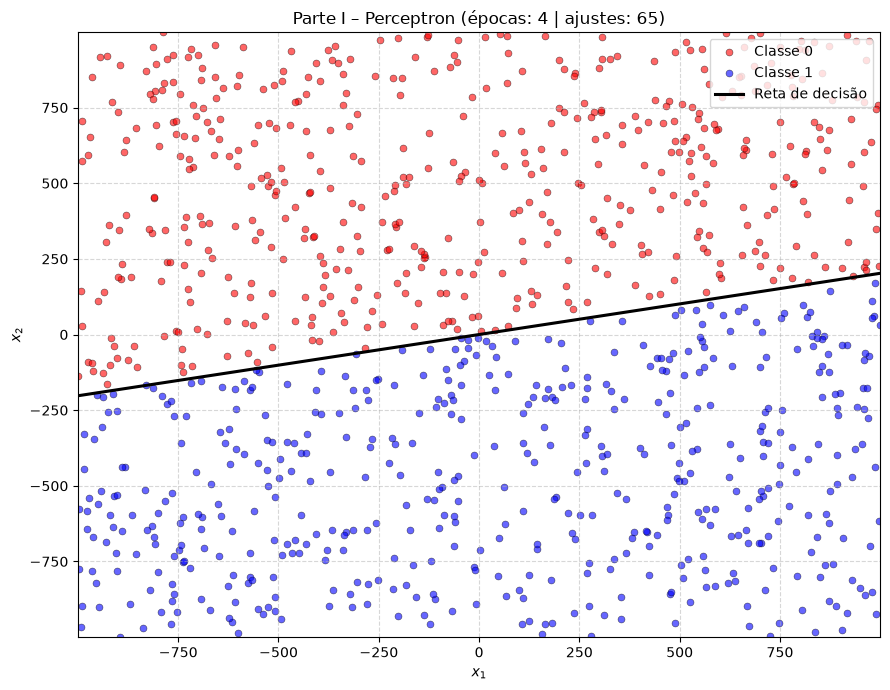

In [2]:
X, y = carregar("dados/dataAll20262.txt")
print("Exemplos:", X.shape[0])
p1 = PerceptronNeuron(learning_rate=0.1, limiar=0.0, weight_range=(-0.5, 0.5))
p1.train(X, y)
p1.plot_decision_boundary(X, y, title=f"Parte I – Perceptron (épocas: {p1.epochs} | ajustes: {p1.total_adjustments})")

## Parte II – Experimentação (`data{ID}20262.txt`)
6 configurações (η × intervalo dos pesos), 10 repetições cada.

In [3]:
X2, y2 = carregar(f"dados/data{ID_EQUIPE}20262.txt")
etas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
N_REP = 10
# Nos dados desta equipe a convergência exige centenas de milhares de épocas (margem pequena).
MAX_EPOCAS = None  # treina até a convergência (rápido graças ao kernel Numba em neuron.py)
rng = np.random.default_rng(ID_EQUIPE)

tabela = PrettyTable(["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes (média ± dp)", "Min Épocas", "Max Épocas", "Convergiram"])
resultados = {}
for eta in etas:
    for inter in intervalos:
        ajustes, epocas, conv = [], [], []
        for _ in range(N_REP):
            n = PerceptronNeuron(learning_rate=eta, limiar=0.0, weight_range=inter)
            n.train(X2, y2, max_epochs=MAX_EPOCAS, rng=rng, verbose=False)
            ajustes.append(n.total_adjustments)
            epocas.append(n.epochs)
            conv.append(bool(np.all(n.predict(X2) == y2)))
        resultados[(eta, inter)] = (np.array(ajustes), np.array(epocas))
        tabela.add_row([f"η = {eta}", f"({inter[0]}, {inter[1]})",
                        f"{np.mean(ajustes):.2f} ± {np.std(ajustes):.2f}", min(epocas), max(epocas), f"{sum(conv)}/{N_REP}"])
print(tabela)

+---------------------+--------------------+---------------------------+------------+------------+-------------+
| Taxa de Aprendizado | Intervalo de Pesos | Qtde Ajustes (média ± dp) | Min Épocas | Max Épocas | Convergiram |
+---------------------+--------------------+---------------------------+------------+------------+-------------+
|       η = 0.4       |    (-100, 100)     |    2813128.90 ± 3611.36   |   239828   |   241613   |    10/10    |
|       η = 0.4       |    (-0.5, 0.5)     |    2811470.70 ± 3147.74   |   239581   |   241625   |    10/10    |
|       η = 0.1       |    (-100, 100)     |    2809699.50 ± 3526.40   |   239634   |   241435   |    10/10    |
|       η = 0.1       |    (-0.5, 0.5)     |    2809532.60 ± 2225.41   |   239688   |   240772   |    10/10    |
|       η = 0.01      |    (-100, 100)     |    2810007.20 ± 6571.25   |   239524   |   241636   |    10/10    |
|       η = 0.01      |    (-0.5, 0.5)     |    2809600.80 ± 3524.13   |   239414   |   241378  

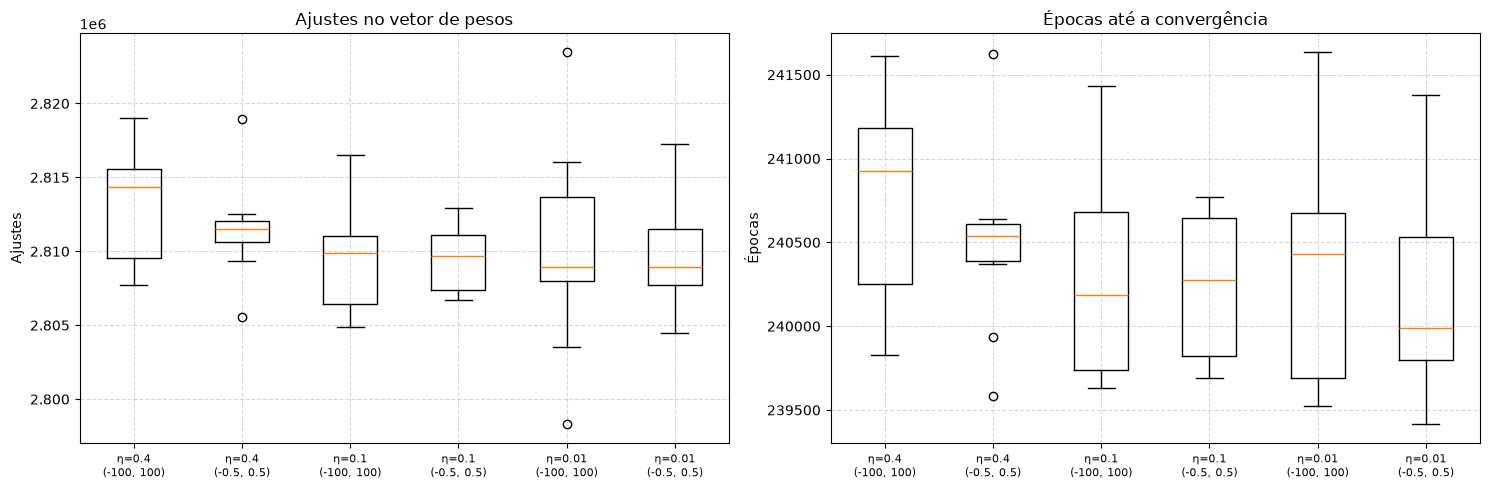

In [4]:
rotulos = [f"η={e}\n{i}" for (e, i) in resultados]
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].boxplot([r[0] for r in resultados.values()], tick_labels=rotulos)
axs[0].set_title("Ajustes no vetor de pesos"); axs[0].set_ylabel("Ajustes")
axs[1].boxplot([r[1] for r in resultados.values()], tick_labels=rotulos)
axs[1].set_title("Épocas até a convergência"); axs[1].set_ylabel("Épocas")
for a in axs: a.grid(True, linestyle="--", alpha=0.5); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### Análise
Nas 60 execuções (6 configurações × 10 repetições) todas convergiram, com cerca de 2,81 milhões de ajustes e entre 239 mil e 242 mil épocas. As médias e os desvios-padrão são praticamente idênticos entre as configurações e os boxplots se sobrepõem por completo.

**Não há evidência de uma configuração melhor ou pior: as seis são equivalentes** para estes dados. Explicações:
- A regra do Perceptron é homogênea: o degrau só depende do sinal de w·x, e cada ajuste soma η·e·x. Com η maior, o vetor w apenas cresce em escala; a fronteira de decisão é a mesma e o número de erros não muda.
- Os dados estão na escala de ±1000 e a margem entre as classes é pequena. Os pesos iniciais (mesmo em (−100, +100)) são desprezíveis diante da magnitude dos ajustes acumulados ao longo de milhões de atualizações, então o intervalo de inicialização também não afeta o resultado.
- O fator determinante é a geometria dos dados (margem pequena em relação ao raio da nuvem), que explica o número elevado de épocas em todas as configurações.

## Parte III – Holdout em problema não-linearmente separável (`dataHoldout20262.txt`)

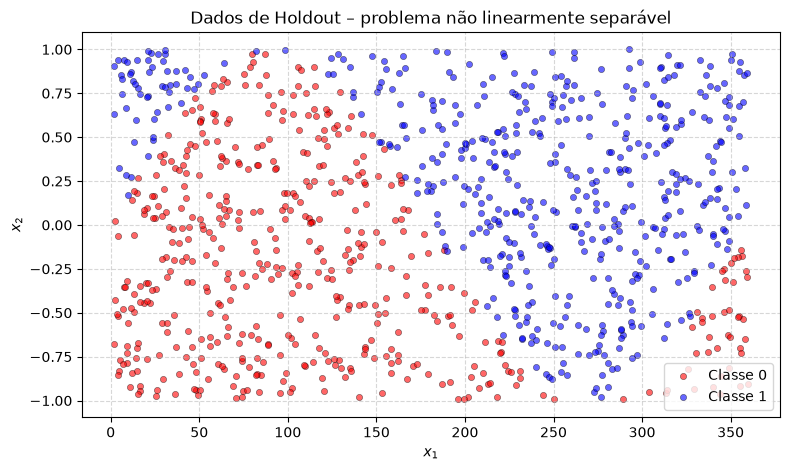

In [5]:
Xh, yh = carregar("dados/dataHoldout20262.txt")
plt.figure(figsize=(9, 5))
plt.scatter(Xh[yh == 0, 0], Xh[yh == 0, 1], color="red", s=20, alpha=0.6, edgecolors="k", linewidths=0.4, label="Classe 0")
plt.scatter(Xh[yh == 1, 0], Xh[yh == 1, 1], color="blue", s=20, alpha=0.6, edgecolors="k", linewidths=0.4, label="Classe 1")
plt.title("Dados de Holdout – problema não linearmente separável")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [6]:
rng = np.random.default_rng(ID_EQUIPE)
idx = rng.permutation(len(Xh))
n_tr = int(0.7 * len(Xh))
tr, te = idx[:n_tr], idx[n_tr:]
Xtr, ytr, Xte, yte = Xh[tr], yh[tr], Xh[te], yh[te]
print("Treino:", len(tr), "| Teste:", len(te))

# η = 0,1 (valor usual na literatura, 0 < η ≤ 1); pesos ~ U(-0,5, 0,5); 100 épocas com embaralhamento
ph = PerceptronNeuron(learning_rate=0.1, limiar=0.0, weight_range=(-0.5, 0.5))
ph.train(Xtr, ytr, max_epochs=100, shuffle=True, rng=rng)

y_pred = ph.predict(Xte)
print("\nMatriz de confusão (teste) [linhas = real, colunas = previsto]:")
print(confusion_matrix(yte, y_pred))
print(f"Acurácia : {accuracy_score(yte, y_pred):.4f}")
print(f"Precisão : {precision_score(yte, y_pred, zero_division=0):.4f}")
print(f"Revocação: {recall_score(yte, y_pred, zero_division=0):.4f}")
print(f"F-Score  : {f1_score(yte, y_pred, zero_division=0):.4f}")
print(f"(Acurácia no treino: {accuracy_score(ytr, ph.predict(Xtr)):.4f})")

Treino: 700 | Teste: 300
Vetor inicial de pesos [w0, w1, w2]: [-0.10152156 -0.00099069 -0.3011742 ]
Vetor final de pesos   [w0, w1, w2]: [658.29847844  22.33914805 600.73848772]
(a) Número total de ajustes no vetor de pesos: 29410
(b) Número de épocas até a convergência:       100

Matriz de confusão (teste) [linhas = real, colunas = previsto]:
[[ 19 125]
 [  2 154]]
Acurácia : 0.5767
Precisão : 0.5520
Revocação: 0.9872
F-Score  : 0.7080
(Acurácia no treino: 0.5729)


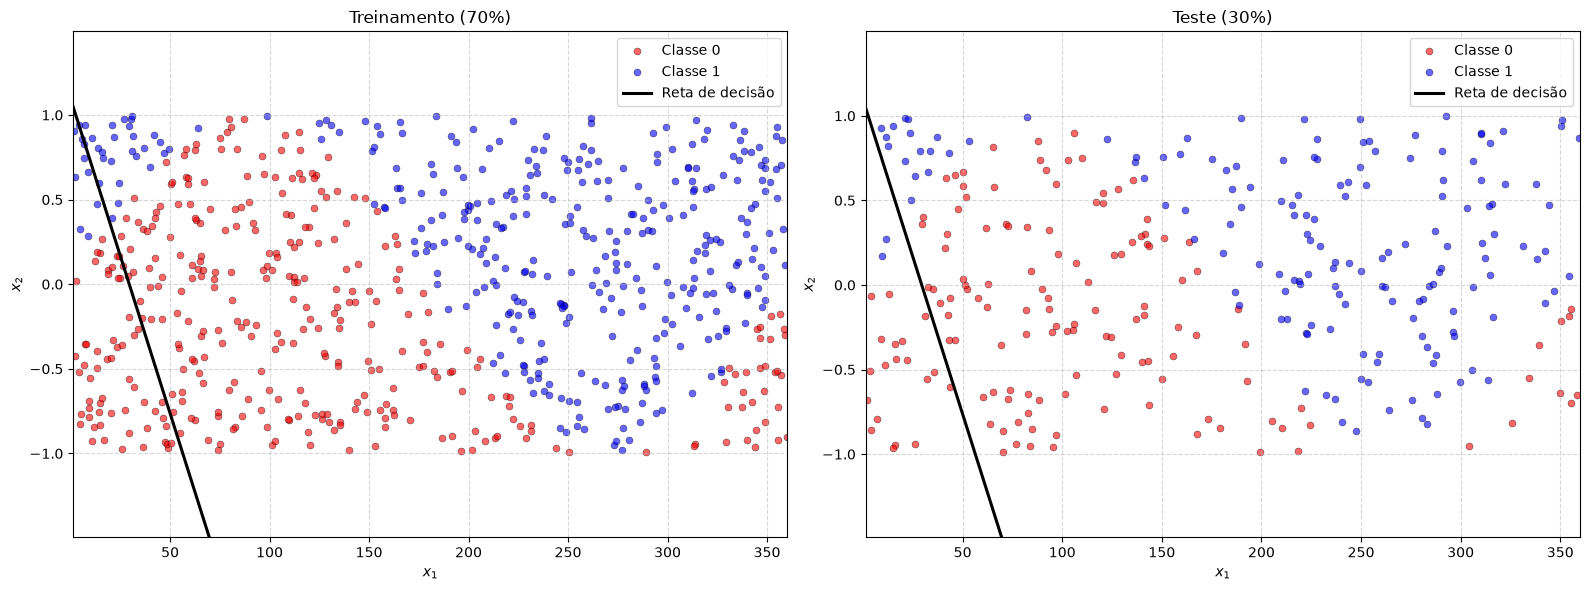

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
ph.plot_decision_boundary(Xtr, ytr, ax=axs[0], title="Treinamento (70%)")
ph.plot_decision_boundary(Xte, yte, ax=axs[1], title="Teste (30%)")
plt.tight_layout(); plt.show()

### Análise da qualidade
Os dados não são linearmente separáveis, então o Perceptron não converge (100 épocas, ~29 mil ajustes) e a reta final é apenas uma solução possível, sem garantia de ótimo.

No conjunto de teste (300 exemplos) a acurácia foi ≈ 0,58, a precisão ≈ 0,55, a revocação ≈ 0,99 e o F-Score ≈ 0,71. A matriz de confusão mostra que o neurônio classifica quase tudo como classe 1: 154 de 156 positivos acertados, mas apenas 19 de 144 negativos (125 falsos positivos). A revocação alta e o F-Score razoável são enganosos: refletem o viés para a classe 1 e não separação real. Com acurácia próxima do acaso (~50%) e acurácia de treino semelhante (~0,57), o modelo linear não captura a estrutura dos dados (sem overfitting, mas com underfitting). A solução é de baixa qualidade; seria necessário um modelo não linear (ex.: MLP).

*Os números citados correspondem à execução com semente 0; se o notebook for reexecutado com outra semente, confira-os.*